In [1]:
%env CUDA_DEVICE_ORDER=PCI_BUS_ID
%env CUDA_VISIBLE_DEVICES=0
%pylab inline
%load_ext autoreload
%autoreload 2

env: CUDA_DEVICE_ORDER=PCI_BUS_ID
env: CUDA_VISIBLE_DEVICES=0
%pylab is deprecated, use %matplotlib inline and import the required libraries.
Populating the interactive namespace from numpy and matplotlib


In [2]:
import numpy as np
import pandas as pd

from pathlib import Path
import re
import os 
import sys
import numpy.core
from IPython.display import display
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

sys.modules["numpy._core"] = numpy.core
sys.modules["numpy._core.multiarray"] = numpy.core.multiarray
sys.modules["numpy._core.numeric"] = numpy.core.numeric

In [3]:
CSV_PATH = Path(
    "/gpfs01/berens/data/data/Eyewire2/morphologies-ew2/csv/main_all_cells/"
    "Eyewire II Proofread Cells Main List - All Cells 2026-11-03.csv"
)

sheet = pd.read_csv(CSV_PATH)

PICKLE_PATH = Path(
    "/gpfs01/berens/data/data/Eyewire2/database-exports/clf_rgcs_and_acs/"
    "df_rgcs_and_acs_2026-11-02-19h.pickle"
)

df = pd.read_pickle(PICKLE_PATH)

/tmp/ipykernel_2573520/115130090.py:6: DtypeWarning: Columns (19,48,49) have mixed types. Specify dtype option on import or set low_memory=False.
  sheet = pd.read_csv(CSV_PATH)


## Remove Problematic cells

In [4]:
df = pd.read_pickle(PICKLE_PATH).reset_index()
df["Index"] = df["rows"].str.split(",")
df = df.explode("Index")  # one row per spreadsheet row; cells with several rows get duplicated
df["Index"]

sheet = pd.read_csv(CSV_PATH, low_memory=False)

In [5]:
FILTER_BAD_CELLS = True
Q = dict(bounds=(200, 1000, 300, 1000),
         max_cant_fix=3, complete_ends_frac=0.95, mostly_complete_ends_frac=0.9,
         huge_hull_diameter=400, large_hull_diameter=300,
         include_if_missing_annots=True, min_hull_diameter=5)

# join on Index; drop sheet columns that already exist in the pickle
sheet = sheet.drop_duplicates("Index")
extra = [c for c in sheet.columns if c not in df.columns or c == "Index"]
df = df.merge(sheet[extra], on="Index", how="left")

# quality flag
df["ends_frac_true"] = df.n_true_end / (df.n_true_end + df.n_cant_fix + df.n_hits_edge)
keep = Q["include_if_missing_annots"]

def ok(s, mask):
    return mask.where(s.notna(), keep)

b = Q["bounds"]
central = df.soma_x_um.between(*b[:2]) & df.soma_y_um.between(*b[2:])
not_broken = ok(df.n_cant_fix, df.n_cant_fix < Q["max_cant_fix"])
complete = ok(df.ends_frac_true, df.ends_frac_true > Q["complete_ends_frac"])
mostly = ok(df.ends_frac_true, df.ends_frac_true > Q["mostly_complete_ends_frac"])
huge = ok(df.hull_diameter, df.hull_diameter > Q["huge_hull_diameter"])
large = ok(df.hull_diameter, df.hull_diameter > Q["large_hull_diameter"])
df["is_quality"] = central & not_broken & (huge | complete | (mostly & large))

if FILTER_BAD_CELLS:
    df = df[df.is_quality & (df.hull_diameter > Q["min_hull_diameter"])].copy()

print(df.shape, f"{df['Index'].isna().sum()} rows without a sheet match")

(19076, 486) 0 rows without a sheet match


In [6]:
df['Reliability Human Label'].value_counts(dropna=False)

NaN       16598
High       2103
Low         277
Medium       98
Name: Reliability Human Label, dtype: int64

keep only high confidence labels and types with more than 10

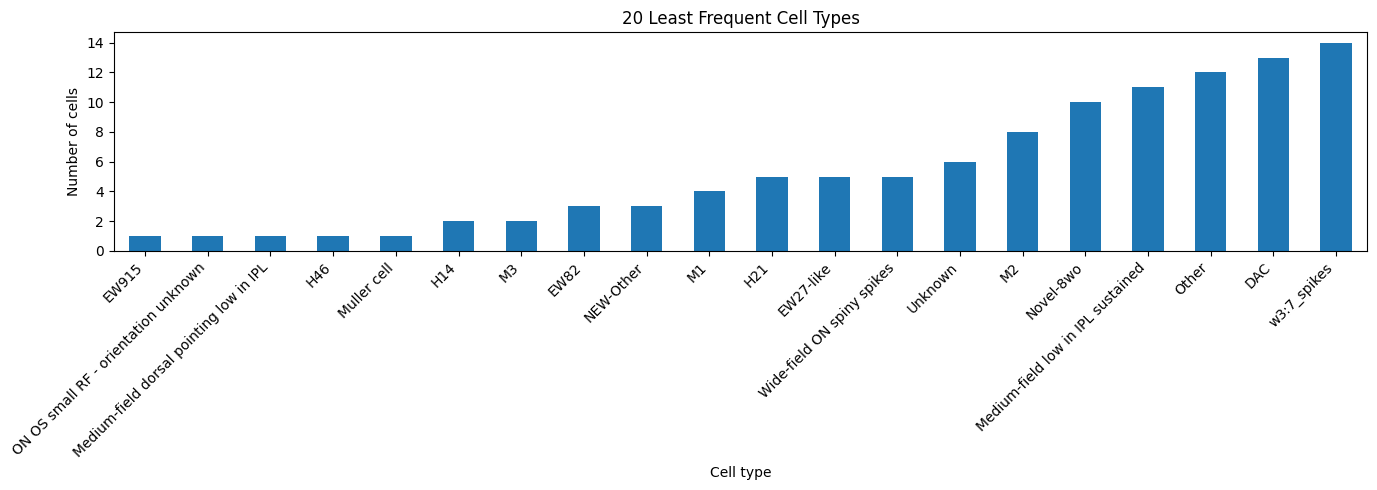

In [7]:
# Keep only high-confidence cells
df = df[df['Reliability Human Label'] == 'High'].copy()

# Keep only cell types with at least 10 cells
high_counts = df['celltype'].value_counts()
valid_celltypes = high_counts[high_counts >= 10].index

df = df[df['celltype'].isin(valid_celltypes)].copy()

(This Reliability Human Label and celltype_conf seem  to be the same)

## Choose the splits

In [8]:
df['celltype_conf'].value_counts()

High    2059
Name: celltype_conf, dtype: int64

In [8]:
summary = (
    df[df["cellclass"] == "RGC"]
    .groupby("celltype")
    .agg(
        total_cells=("celltype", "size"),
        high_conf=("celltype_conf", lambda x: (x == "High").sum()),
        mid_conf=("celltype_conf", lambda x: (x == "Medium").sum()),
        low_conf=("celltype_conf", lambda x: (x == "Low").sum())
    )
    .sort_values("total_cells")
)


display(summary)

,total_cells,high_conf,mid_conf,low_conf
celltype,,,,
Novel-8wo,10,10,0,0
ON small OFF large,12,12,0,0
EW82wo,13,13,0,0
M6,14,14,0,0
OFF sustained EW3o,15,15,0,0
Sustained suppressed-by-contrast no surround EW27,16,16,0,0
EW3o-like,16,16,0,0
EW28-like,17,17,0,0
EW82wi,17,17,0,0


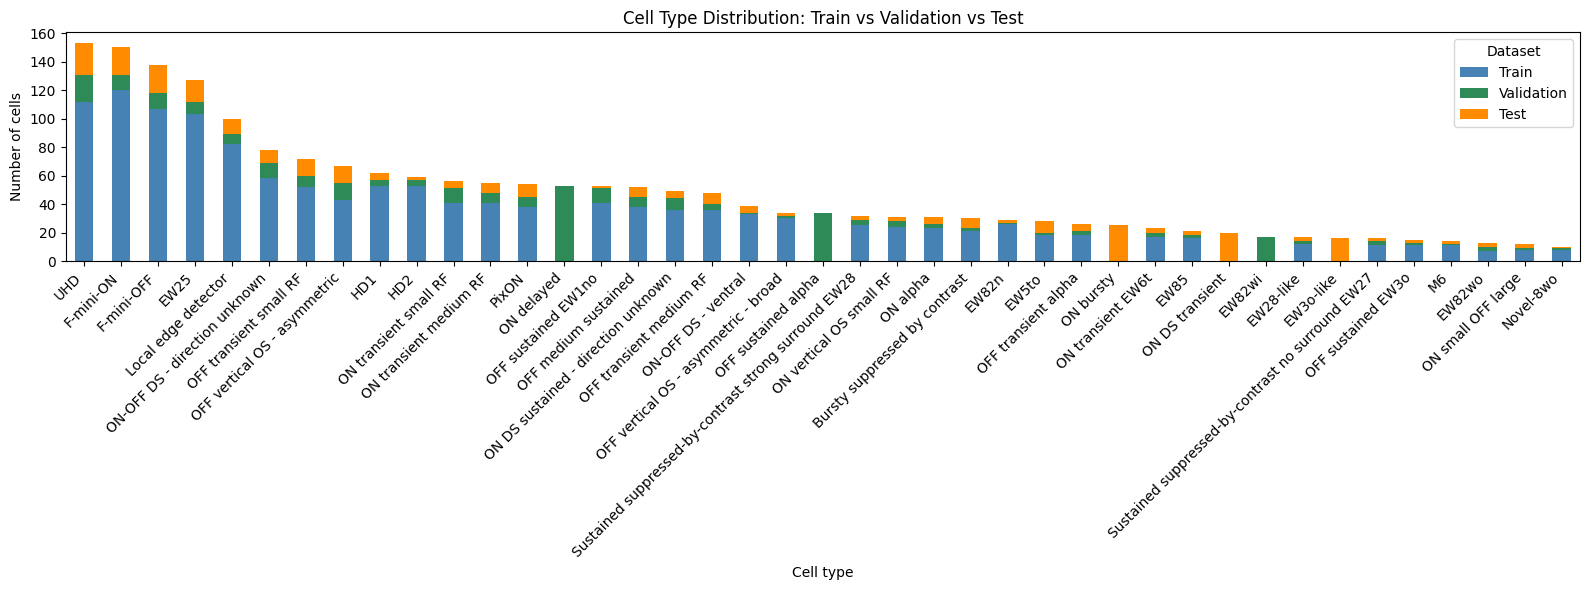

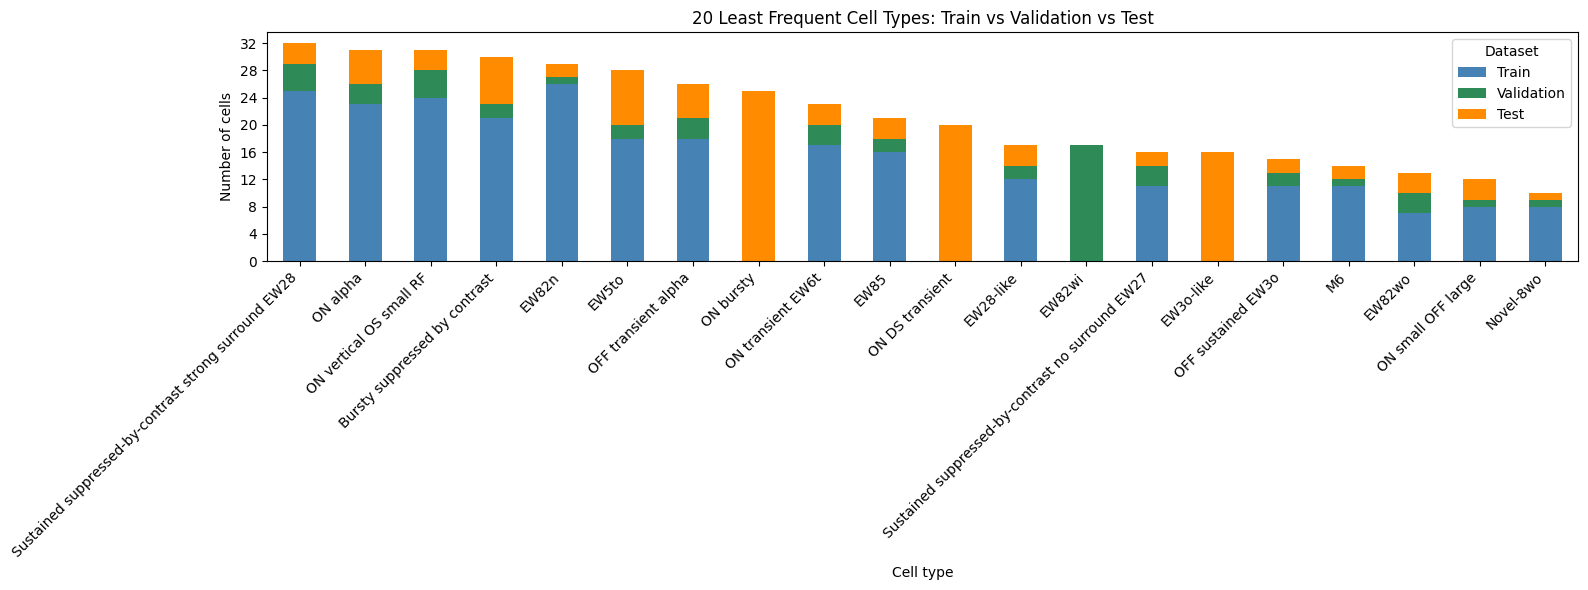

In [68]:
def split_cells(
    df,
    heldout_test_types,
    heldout_val_types,
    seed=42,
    split_ratio=0.15,
    min_cells_per_type=5
):
    rng = np.random.default_rng(seed)

    df = df[
        df["cellclass"] == "RGC"
    ].copy().reset_index(drop=True)

    df["cell_id"] = df["skel_file"].apply(
        lambda x: os.path.splitext(os.path.basename(x))[0]
    )

    heldout_test_types = list(heldout_test_types)
    heldout_val_types = list(heldout_val_types)

    heldout_types = heldout_test_types + heldout_val_types

    # These cells will ONLY go into training
    unknown_type_cells = df[
        df["celltype"].isna()
    ].copy()

    # Only known cell types can be assigned to held-out groups
    known_type_cells = df[
        df["celltype"].notna()
    ].copy()

    # Every cell of these types goes to test
    test_heldout = known_type_cells[
        known_type_cells["celltype"].isin(heldout_test_types)
    ].copy()

    # Every cell of these types goes to validation
    val_heldout = known_type_cells[
        known_type_cells["celltype"].isin(heldout_val_types)
    ].copy()

    # Only non-held-out cells with known celltypes can be sampled
    remaining = known_type_cells[
        ~known_type_cells["celltype"].isin(heldout_types)
    ].copy()

    n_total = len(df)

    target_val = round(n_total * split_ratio)
    target_test = round(n_total * split_ratio)

    n_val_needed = target_val - len(val_heldout)
    n_test_needed = target_test - len(test_heldout)

    if n_val_needed < 0:
        raise ValueError(
            f"All held-out validation cells ({len(val_heldout)}) "
            f"exceed the validation target ({target_val})."
        )

    if n_test_needed < 0:
        raise ValueError(
            f"All held-out test cells ({len(test_heldout)}) "
            f"exceed the test target ({target_test})."
        )

    type_counts = remaining["celltype"].value_counts()

    eligible_types = type_counts[
        type_counts >= min_cells_per_type
    ].index.tolist()

    eligible = remaining[
        remaining["celltype"].isin(eligible_types)
    ].copy()

    # Ensure each eligible type can appear in both splits
    if n_val_needed < len(eligible_types):
        raise ValueError(
            "Not enough validation slots to include every "
            "eligible cell type."
        )

    if n_test_needed < len(eligible_types):
        raise ValueError(
            "Not enough test slots to include every "
            "eligible cell type."
        )

    val_indices = []
    test_indices = []

    for cell_type in eligible_types:

        type_data = eligible[
            eligible["celltype"] == cell_type
        ].copy()

        # Shuffle within confidence groups
        high = type_data[
            type_data["celltype_conf"] == "High"
        ]

        other = type_data[
            type_data["celltype_conf"] != "High"
        ]

        high_indices = high.index.to_numpy().copy()
        other_indices = other.index.to_numpy().copy()

        rng.shuffle(high_indices)
        rng.shuffle(other_indices)

        ordered_indices = np.concatenate([
            high_indices,
            other_indices
        ])

        # Reserve two distinct cells
        val_indices.append(ordered_indices[0])
        test_indices.append(ordered_indices[1])

    used_indices = set(val_indices) | set(test_indices)

    available = eligible.loc[
        ~eligible.index.isin(used_indices)
    ].copy()

    # Prioritize High, then Medium, Low, and missing confidence
    confidence_order = ["High", "Medium", "Low"]

    candidate_groups = []

    for confidence in confidence_order:
        group = available[
            available["celltype_conf"] == confidence
        ].index.to_numpy().copy()

        rng.shuffle(group)
        candidate_groups.append(group)

    # Include missing or other confidence values last
    other_confidence = available[
        ~available["celltype_conf"].isin(confidence_order)
    ].index.to_numpy().copy()

    rng.shuffle(other_confidence)
    candidate_groups.append(other_confidence)

    candidates = np.concatenate(candidate_groups)

    n_val_extra = n_val_needed - len(val_indices)
    n_test_extra = n_test_needed - len(test_indices)

    n_extra_total = n_val_extra + n_test_extra

    if n_extra_total > len(candidates):
        raise ValueError(
            "Not enough remaining cells to reach the requested "
            "validation and test sizes."
        )

    extra_indices = candidates[:n_extra_total]

    val_extra = extra_indices[:n_val_extra]
    test_extra = extra_indices[n_val_extra:]

    val_indices.extend(val_extra.tolist())
    test_indices.extend(test_extra.tolist())

    val_sampled = remaining.loc[val_indices].copy()
    test_sampled = remaining.loc[test_indices].copy()

    val = pd.concat(
        [val_heldout, val_sampled],
        axis=0
    )

    test = pd.concat(
        [test_heldout, test_sampled],
        axis=0
    )

    assigned_indices = set(val.index) | set(test.index)

    train = df.loc[
        ~df.index.isin(assigned_indices)
    ].copy()

    # This includes ALL cells with missing celltype
    assert unknown_type_cells.index.isin(train.index).all()


    train = train.sample(
        frac=1,
        random_state=seed
    ).reset_index(drop=True)

    val = val.sample(
        frac=1,
        random_state=seed
    ).reset_index(drop=True)

    test = test.sample(
        frac=1,
        random_state=seed
    ).reset_index(drop=True)

    train_ids = set(train["cell_id"])
    val_ids = set(val["cell_id"])
    test_ids = set(test["cell_id"])

    original_ids = set(df["cell_id"])

    overlap = train_ids.intersection(test_ids)

    print("Number of overlapping cell IDs:", len(overlap))
    print(df[df["cell_id"].isin(overlap)][
        ["cell_id", "celltype", "celltype_conf"]
    ].sort_values("cell_id"))
    assert train_ids.isdisjoint(val_ids), "Train/val overlap!"
    assert train_ids.isdisjoint(test_ids), "Train/test overlap!"
    assert val_ids.isdisjoint(test_ids), "Val/test overlap!"

    all_assigned_ids = train_ids | val_ids | test_ids

    missing_ids = original_ids - all_assigned_ids
    extra_ids = all_assigned_ids - original_ids

    assert not missing_ids, f"Missing cells: {len(missing_ids)}"
    assert not extra_ids, f"Unexpected cells: {len(extra_ids)}"

    assert len(train) + len(val) + len(test) == len(df)

    # All missing-celltype cells must be in training
    unknown_ids = set(unknown_type_cells["cell_id"])

    assert unknown_ids.issubset(train_ids)
    assert not unknown_ids.intersection(val_ids)
    assert not unknown_ids.intersection(test_ids)

    # Held-out types must only appear in their designated split
    assert not train["celltype"].isin(heldout_types).any()

    assert not val["celltype"].isin(heldout_test_types).any()
    assert not test["celltype"].isin(heldout_val_types).any()

    # Check that every held-out cell is present
    assert set(test_heldout["cell_id"]).issubset(test_ids)
    assert set(val_heldout["cell_id"]).issubset(val_ids)


    print("\nSPLIT SUMMARY")
    print("----------------------------")
    print(f"Total RGC cells: {len(df)}")
    print(f"Train:      {len(train)} ({len(train)/len(df):.2%})")
    print(f"Validation: {len(val)} ({len(val)/len(df):.2%})")
    print(f"Test:       {len(test)} ({len(test)/len(df):.2%})")

    print("\nCells with missing celltype:")
    print(f"Assigned to training: {len(unknown_type_cells)}")

    print("\nHeld-out validation types:", heldout_val_types)
    print("Held-out test types:", heldout_test_types)

    print("\nHeld-out validation counts:")
    print(
        val[val["celltype"].isin(heldout_val_types)]
        .groupby("celltype").size()
    )

    print("\nHeld-out test counts:")
    print(
        test[test["celltype"].isin(heldout_test_types)]
        .groupby("celltype").size()
    )

    return train, val, test, heldout_val_types, heldout_test_types


In [72]:
df = df.drop_duplicates(subset="cell").copy().reset_index(drop=True)

In [73]:
train, val, test, heldout_val_types, heldout_test_types = split_cells(
    df,
    heldout_test_types=["ON DS transient", "EW3o-like", "ON bursty"],
    heldout_val_types=["EW82wi", "OFF sustained alpha", "ON delayed"],
    seed=42,
    split_ratio=0.15
)

Number of overlapping cell IDs: 0
Empty DataFrame
Columns: [cell_id, celltype, celltype_conf]
Index: []

SPLIT SUMMARY
----------------------------
Total RGC cells: 1955
Train:      1369 (70.03%)
Validation: 293 (14.99%)
Test:       293 (14.99%)

Cells with missing celltype:
Assigned to training: 0

Held-out validation types: ['EW82wi', 'OFF sustained alpha', 'ON delayed']
Held-out test types: ['ON DS transient', 'EW3o-like', 'ON bursty']

Held-out validation counts:
celltype
EW82wi                 17
OFF sustained alpha    34
ON delayed             53
dtype: int64

Held-out test counts:
celltype
EW3o-like          16
ON DS transient    20
ON bursty          25
dtype: int64


In [74]:
np.save("train_ids.npy", train["cell_id"].to_numpy(dtype=str))
np.save("val_ids.npy", val["cell_id"].to_numpy(dtype=str))
np.save("test_ids.npy", test["cell_id"].to_numpy(dtype=str))

print("Saved:")
print("Train:", len(train), "cells")
print("Validation:", len(val), "cells")
print("Test:", len(test), "cells")

Saved:
Train: 1369 cells
Validation: 293 cells
Test: 293 cells


Remove cells with less than 1000 nodes after axon removal (during extraction)

In [76]:
cell_id_to_remove = "720575940560435035"

train = train[train["cell_id"] != cell_id_to_remove].copy()
val = val[val["cell_id"] != cell_id_to_remove].copy()
test = test[test["cell_id"] != cell_id_to_remove].copy()

print("Train:", len(train))
print("Val:", len(val))
print("Test:", len(test))

Train: 1369
Val: 293
Test: 293


In [77]:
np.save("train_ids.npy", train["cell_id"].to_numpy(dtype=str))
np.save("val_ids.npy", val["cell_id"].to_numpy(dtype=str))
np.save("test_ids.npy", test["cell_id"].to_numpy(dtype=str))

In [78]:
all_ids = np.concatenate([
    train["cell_id"].to_numpy(dtype=str),
    val["cell_id"].to_numpy(dtype=str),
    test["cell_id"].to_numpy(dtype=str)
])


np.save("all_ids.npy", all_ids)

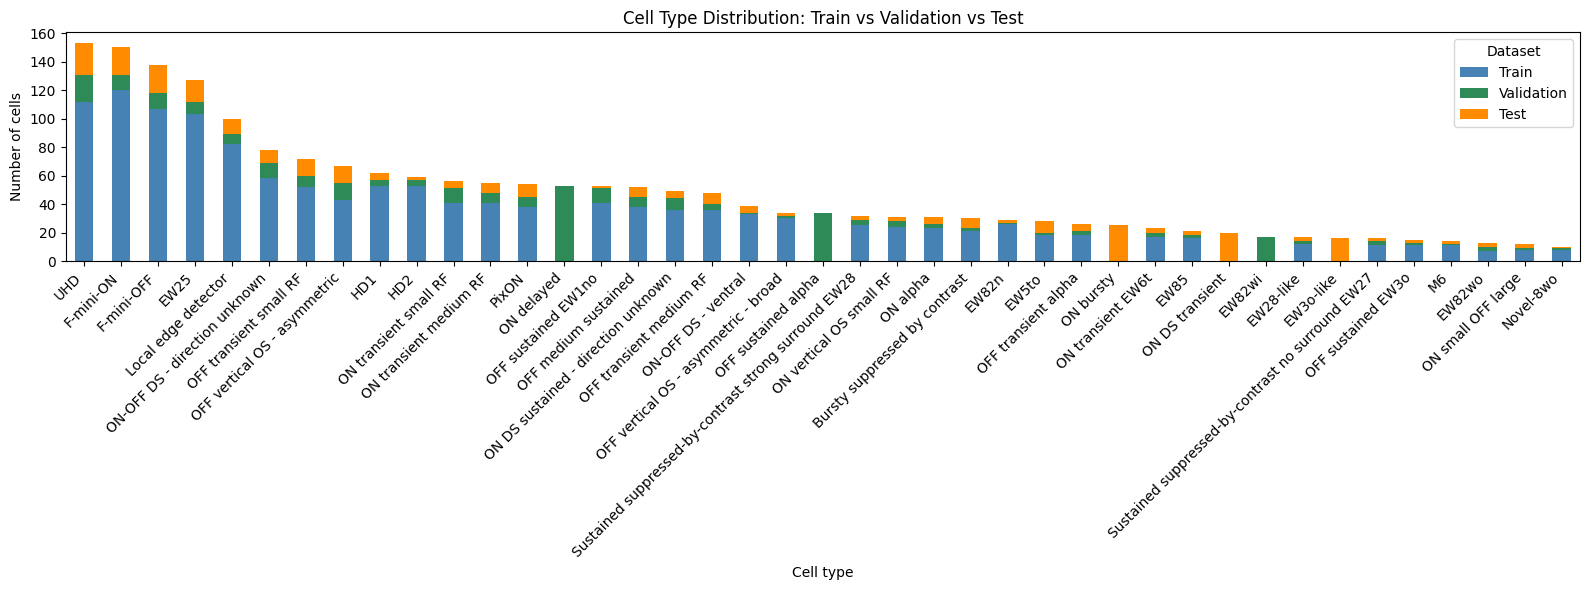

In [31]:
train_ids = np.load("train_ids.npy").astype(np.int64)
test_ids = np.load("test_ids.npy").astype(np.int64)
val_ids = np.load("val_ids.npy").astype(np.int64)

train_counts = df[df["cell"].isin(train_ids)]["celltype"].value_counts()
test_counts = df[df["cell"].isin(test_ids)]["celltype"].value_counts()
val_counts = df[df["cell"].isin(val_ids)]["celltype"].value_counts()

counts = pd.DataFrame({
    "Train": train_counts,
    "Validation": val_counts,
    "Test": test_counts
}).fillna(0)

counts["Total"] = counts.sum(axis=1)
counts = counts.sort_values("Total", ascending=False)

counts[["Train", "Validation", "Test"]].plot(
    kind="bar",
    stacked=True,
    figsize=(16, 6),
    color=["steelblue", "seagreen", "darkorange"]
)

plt.xlabel("Cell type")
plt.ylabel("Number of cells")
plt.title("Cell Type Distribution: Train vs Validation vs Test")
plt.xticks(rotation=45, ha="right")
plt.gca().yaxis.set_major_locator(ticker.MaxNLocator(integer=True))
plt.legend(title="Dataset")
plt.tight_layout()
plt.show()

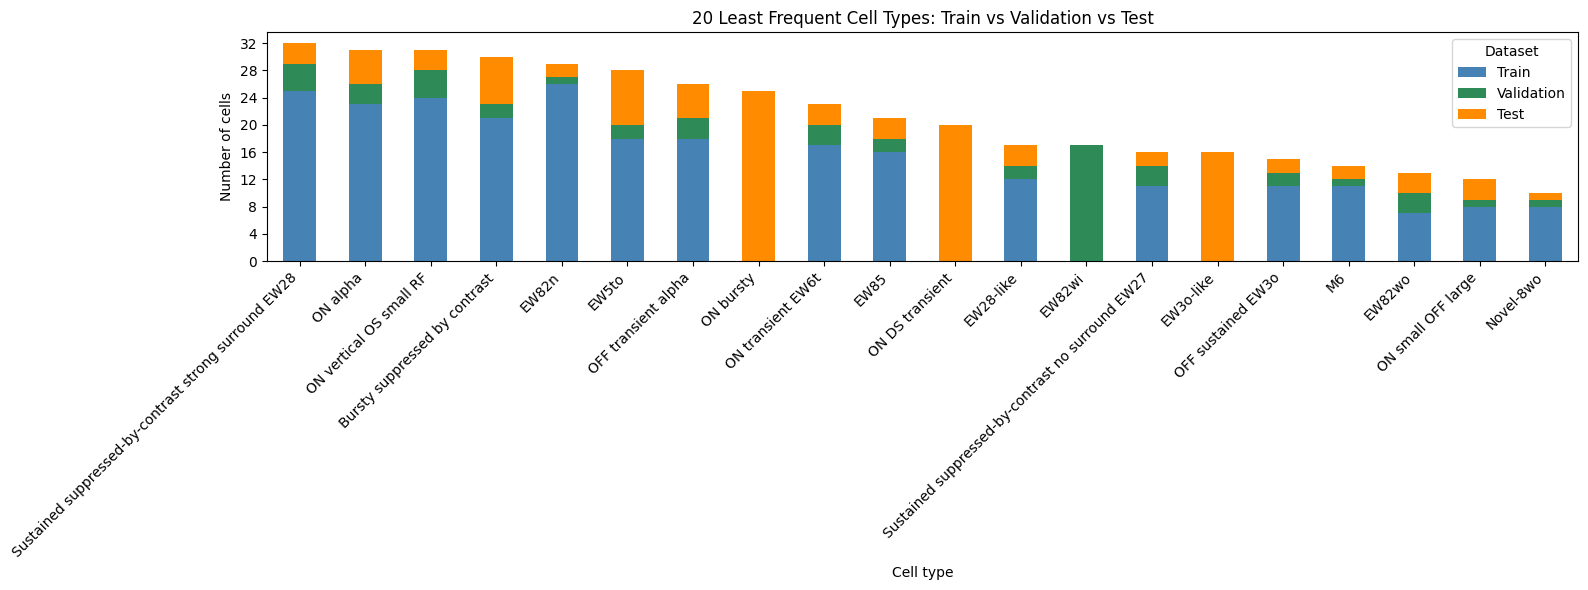

In [32]:

least_20 = counts.nsmallest(20, "Total").sort_values("Total", ascending=False)

least_20[["Train", "Validation", "Test"]].plot(
    kind="bar",
    stacked=True,
    figsize=(16, 6),
    color=["steelblue", "seagreen", "darkorange"]
)

plt.xlabel("Cell type")
plt.ylabel("Number of cells")
plt.title("20 Least Frequent Cell Types: Train vs Validation vs Test")
plt.xticks(rotation=45, ha="right")
plt.gca().yaxis.set_major_locator(ticker.MaxNLocator(integer=True))
plt.legend(title="Dataset")
plt.tight_layout()
plt.show()